# Time Series Analysis - Homework 3: Baseline Forecasts for Walmart Departments
> **Author:** Elias Schweighuber  
> **Course:** TIS  
>
> **Goal:** Forecast monthly revenue for the seven Walmart departments using baseline models.  
> **Windows:**  
> - **Validation:** Training on 2012-01 to 2013-12 (24 months), forecasting 2014 ($h = 12$).  
> - **Test:** Training on 2012-01 to 2014-12 (36 months), forecasting 2015 ($h = 12$).


## Step 1 - Prepare the Data
We load the M5 Walmart transaction data from `sales_combined.parquet`, `calendar.csv`, and `sell_prices.csv`.
Only the four complete calendar years **2012-01-01 to 2015-12-31** (48 complete months) are kept; 2011 and 2016 are dropped.
We calculate transaction revenue ($	ext{sales} 	imes 	ext{sell\_price}$) and aggregate monthly revenue for each of the seven departments (`FOODS_1`, `FOODS_2`, `FOODS_3`, `HOBBIES_1`, `HOBBIES_2`, `HOUSEHOLD_1`, `HOUSEHOLD_2`) plus total revenue across all departments.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt

# 1. Locate data directory robustly
data_dir = Path("../hw1/data")
if not data_dir.exists():
    data_dir = Path("tis/hw1/data")
if not data_dir.exists():
    data_dir = Path("data")

print(f"Loading data from: {data_dir.resolve()}")

# 2. Identify 4 complete years: 2012-01-01 to 2015-12-31
sales_lazy = pl.scan_parquet(data_dir / "sales_combined.parquet")
all_cols = sales_lazy.collect_schema().names()
index_cols = ["item_id", "dept_id", "cat_id", "store_id", "state_id"]
date_cols = [c for c in all_cols if c not in index_cols and "2012-01-01" <= c <= "2015-12-31"]

# 3. Unpivot sales to long format and join with calendar & prices
long_sales = sales_lazy.select(index_cols + date_cols).unpivot(
    index=index_cols,
    on=date_cols,
    variable_name="date",
    value_name="sales"
)

calendar = pl.scan_csv(data_dir / "calendar.csv").select(["date", "wm_yr_wk"])
sell_prices = pl.scan_csv(data_dir / "sell_prices.csv")

dept_monthly_df = (
    long_sales
    .join(calendar, on="date", how="left")
    .join(sell_prices, on=["store_id", "item_id", "wm_yr_wk"], how="left")
    .with_columns(
        (pl.col("sales").fill_null(0).cast(pl.Float64) * pl.col("sell_price").fill_null(0.0)).alias("revenue"),
        pl.col("date").str.slice(0, 7).alias("month")
    )
    .group_by(["dept_id", "month"])
    .agg(pl.col("revenue").sum())
    .sort(["dept_id", "month"])
    .collect()
    .to_pandas()
)

# 4. Pivot to Month x Department table and add Total column
df_monthly = dept_monthly_df.pivot(index="month", columns="dept_id", values="revenue")
df_monthly["Total"] = df_monthly.sum(axis=1)

print(f"Data prepared: {df_monthly.shape[0]} months ({df_monthly.index[0]} to {df_monthly.index[-1]}) across {df_monthly.shape[1]} series.")


Loading data from: C:\Users\elias\PycharmProjects\notebooks\tis\hw1\data
Data prepared: 48 months (2012-01 to 2015-12) across 8 series.


### Total Revenue per Department
As requested in Step 1, here is the total revenue per department for:
1. **Whole period:** 2012 to 2015 (48 months)
2. **Validation period:** 2014 (12 months)
3. **Test period:** 2015 (12 months)


In [2]:
# Revenue summary table
rev_total = df_monthly.sum(axis=0)
rev_2014 = df_monthly[[c for c in df_monthly.index if c.startswith("2014")]].sum(axis=0) if False else df_monthly.loc["2014-01":"2014-12"].sum(axis=0)
rev_2015 = df_monthly.loc["2015-01":"2015-12"].sum(axis=0)

summary_revenue = pd.DataFrame({
    "Total (2012-2015)": rev_total,
    "Validation (2014)": rev_2014,
    "Test (2015)": rev_2015
})

# Display formatted table
summary_formatted = summary_revenue.map(lambda x: f"${x:,.2f}")
display(summary_formatted)


,Total (2012-2015),Validation (2014),Test (2015)
dept_id,,,
FOODS_1,"$10,366,108.39","$2,571,890.70","$2,909,513.26"
FOODS_2,"$19,307,253.35","$4,788,218.92","$5,870,560.70"
FOODS_3,"$56,412,124.05","$14,744,482.37","$14,615,472.95"
HOBBIES_1,"$17,272,045.51","$4,192,736.88","$5,594,830.17"
HOBBIES_2,"$937,831.65","$257,027.41","$301,934.92"
HOUSEHOLD_1,"$33,134,253.96","$8,409,942.41","$9,952,790.00"
HOUSEHOLD_2,"$11,421,327.04","$2,897,614.50","$3,171,354.61"
Total,"$148,850,943.95","$37,861,913.19","$42,416,456.61"


## Step 2 - Build the Baselines
We implement six baseline forecasting methods from scratch. Each function receives only the training array `y` and forecast horizon `h=12`, returning exactly 12 forecasted values:

1. **Naive:** Carries the last training month forward:
   $$\hat{y}_{T+h} = y_T$$
2. **Historic Average:** Mean of all observed training values:
   $$\hat{y}_{T+h} = \frac{1}{T}\sum_{t=1}^T y_t$$
3. **Seasonal Naive:** Carries forward the value from the same calendar month of the previous year:
   $$\hat{y}_{T+h} = y_{T - 12 + h}$$
4. **Linear Trend (Drift):** Extends the linear trend between the first and last training observations:
   $$\hat{y}_{T+h} = y_T + h \cdot \frac{y_T - y_1}{T - 1}$$
5. **Random Draw:** Simulates $N = 1,000$ paths by drawing months uniformly at random with replacement from the training window, summarized by the Monte Carlo mean:
   $$\hat{y}_{T+h} = \frac{1}{N} \sum_{s=1}^N y^{(s)}_h, \quad y^{(s)}_h \sim \text{Uniform}(\{y_1, \dots, y_T\})$$
6. **Structural (Seasonal Drift):** Combines the annual repeating seasonal pattern with the estimated linear drift:
   $$\hat{y}_{T+h} = y_{T - 12 + h} + 12 \cdot \frac{y_T - y_1}{T - 1}$$
   This baseline projects the previous year's seasonal profile shifted upward by one year's worth of drift rate, capturing both intra-year seasonal swings and year-over-year growth.


In [3]:
def naive_forecast(y: np.ndarray, h: int = 12) -> np.ndarray:
    """Carry the last training month forward."""
    return np.full(h, y[-1], dtype=float)

def historic_average_forecast(y: np.ndarray, h: int = 12) -> np.ndarray:
    """The mean of the training window."""
    return np.full(h, np.mean(y), dtype=float)

def seasonal_naive_forecast(y: np.ndarray, h: int = 12) -> np.ndarray:
    """The same month one year earlier (last 12 training months)."""
    return y[-12:].copy().astype(float)

def linear_trend_forecast(y: np.ndarray, h: int = 12) -> np.ndarray:
    """The last value plus the average monthly change (drift)."""
    slope = (y[-1] - y[0]) / (len(y) - 1)
    return y[-1] + np.arange(1, h + 1, dtype=float) * slope

def random_draw_forecast(y: np.ndarray, h: int = 12, n_sims: int = 1000, seed: int = 42) -> np.ndarray:
    """Each month drawn at random from training values, summarized by simulation mean."""
    rng = np.random.default_rng(seed)
    sims = rng.choice(y, size=(n_sims, h), replace=True)
    return np.mean(sims, axis=0)

def structural_forecast(y: np.ndarray, h: int = 12) -> np.ndarray:
    """Seasonal Naive adjusted for linear annual drift (Trend + Seasonality)."""
    slope = (y[-1] - y[0]) / (len(y) - 1)
    return y[-12:].astype(float) + 12.0 * slope

# Dictionary of all baseline models
baseline_models = {
    "Naive": naive_forecast,
    "Historic average": historic_average_forecast,
    "Seasonal naive": seasonal_naive_forecast,
    "Linear trend (drift)": linear_trend_forecast,
    "Random draw": random_draw_forecast,
    "Structural": structural_forecast,
}


## Step 3 - Measure the Error
For each baseline model, we compute the following seven error metrics over the 12-month horizon:

1. **MAE:** $\frac{1}{H}\sum_{h=1}^H |y_h - \hat{y}_h|$
2. **RMSE:** $\sqrt{\frac{1}{H}\sum_{h=1}^H (y_h - \hat{y}_h)^2}$
3. **MAPE (%):** $\frac{100\%}{H}\sum_{h=1}^H \left|\frac{y_h - \hat{y}_h}{y_h}\right|$
4. **wMAPE (%):** $\frac{\sum_{h=1}^H |y_h - \hat{y}_h|}{\sum_{h=1}^H y_h} \times 100\%$ (volume-weighted absolute percentage error)
5. **R²:** $1 - \frac{\sum_{h=1}^H (y_h - \hat{y}_h)^2}{\sum_{h=1}^H (y_h - \bar{y})^2}$ (can be negative when forecast is worse than the actual mean $\bar{y}$)
6. **Bias:** $\frac{1}{H}\sum_{h=1}^H (\hat{y}_h - y_h)$ (positive indicates systematic overforecasting; negative indicates underforecasting)
7. **MASE:** $\frac{\text{MAE}}{\frac{1}{T-12}\sum_{t=13}^T |y_t - y_{t-12}|}$ (scaled by the in-sample Seasonal Naive MAE over the training period)

We report one table per baseline with one row per department plus **Total** as an extra row, for both the **Validation window (2014)** and the **Test window (2015)**.


In [4]:
def compute_metrics(y_true: np.ndarray, y_pred: np.ndarray, y_train: np.ndarray) -> dict:
    """Compute MAE, RMSE, MAPE, wMAPE, R2, bias, and seasonal MASE."""
    err = y_true - y_pred
    mae = float(np.mean(np.abs(err)))
    rmse = float(np.sqrt(np.mean(err ** 2)))
    mape = float(np.mean(np.abs(err / y_true)) * 100.0)
    wmape = float(np.sum(np.abs(err)) / np.sum(y_true) * 100.0)
    
    ss_res = np.sum(err ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    r2 = float(1.0 - ss_res / ss_tot) if ss_tot != 0 else np.nan
    bias = float(np.mean(y_pred - y_true))
    
    # In-sample seasonal naive MAE scale (m=12)
    scale = float(np.mean(np.abs(y_train[12:] - y_train[:-12])))
    mase = float(mae / scale) if scale != 0 else np.nan
    
    return {
        "MAE": mae,
        "RMSE": rmse,
        "MAPE (%)": mape,
        "wMAPE (%)": wmape,
        "R2": r2,
        "bias": bias,
        "MASE": mase,
    }

def format_metrics_table(table_df: pd.DataFrame) -> pd.DataFrame:
    """Format numbers for clean presentation."""
    formatted = table_df.copy()
    for col in ["MAE", "RMSE", "bias"]:
        formatted[col] = formatted[col].apply(lambda x: f"${x:,.2f}" if abs(x) >= 1e4 else f"${x:,.2f}")
    for col in ["MAPE (%)", "wMAPE (%)"]:
        formatted[col] = formatted[col].apply(lambda x: f"{x:.2f}%")
    for col in ["R2", "MASE"]:
        formatted[col] = formatted[col].apply(lambda x: f"{x:.3f}")
    return formatted

def build_baseline_tables(df: pd.DataFrame, train_start: int, train_end: int, test_start: int, test_end: int):
    """Build error tables for all baseline models across all series."""
    series_names = [c for c in df.columns if c != "Total"] + ["Total"]
    results = {}
    
    for mname, mfn in baseline_models.items():
        rows = []
        for sname in series_names:
            y_train = df[sname].iloc[train_start:train_end].values
            y_eval = df[sname].iloc[test_start:test_end].values
            
            y_pred = mfn(y_train, h=len(y_eval))
            m = compute_metrics(y_eval, y_pred, y_train)
            rows.append({"Department": sname, **m})
            
        res_df = pd.DataFrame(rows).set_index("Department")
        results[mname] = res_df
        
    return results


In [5]:
# Compute error tables for Validation (2014)
# Train: 2012-01 to 2013-12 (indices 0:24), Forecast: 2014-01 to 2014-12 (indices 24:36)
val_tables = build_baseline_tables(df_monthly, train_start=0, train_end=24, test_start=24, test_end=36)

print("=" * 80)
print("ERROR TABLES FOR VALIDATION WINDOW (2014)")
print("=" * 80)

for mname, tbl in val_tables.items():
    print(f"\n--- Baseline: {mname} (Validation 2014) ---")
    display(format_metrics_table(tbl))


ERROR TABLES FOR VALIDATION WINDOW (2014)

--- Baseline: Naive (Validation 2014) ---


,MAE,RMSE,MAPE (%),wMAPE (%),R2,bias,MASE
Department,,,,,,,
FOODS_1,"$23,614.07","$24,983.27",11.24%,11.02%,-2.220,"$20,743.70",1.641
FOODS_2,"$58,030.04","$69,652.03",13.77%,14.54%,-2.269,"$-58,030.04",1.626
FOODS_3,"$98,610.75","$111,658.82",7.84%,8.03%,-1.794,"$-89,475.07",1.221
HOBBIES_1,"$12,868.40","$17,221.50",3.76%,3.68%,-0.014,"$-2,044.71",0.171
HOBBIES_2,"$4,333.94","$6,597.51",16.54%,20.23%,-0.410,"$-3,557.46",2.091
HOUSEHOLD_1,"$77,501.58","$86,344.22",10.79%,11.06%,-4.146,"$-77,501.58",0.739
HOUSEHOLD_2,"$22,309.69","$26,191.50",8.89%,9.24%,-1.324,"$-19,767.97",1.284
Total,"$241,553.50","$267,382.79",7.51%,7.66%,-2.811,"$-229,633.15",0.885



--- Baseline: Historic average (Validation 2014) ---


,MAE,RMSE,MAPE (%),wMAPE (%),R2,bias,MASE
Department,,,,,,,
FOODS_1,"$12,579.51","$17,617.95",5.57%,5.87%,-0.601,"$-10,794.87",0.874
FOODS_2,"$41,414.20","$54,579.43",9.66%,10.38%,-1.007,"$-38,665.17",1.161
FOODS_3,"$108,659.16","$121,535.54",8.63%,8.84%,-2.310,"$-101,533.17",1.346
HOBBIES_1,"$38,596.55","$41,252.41",10.86%,11.05%,-4.820,"$-37,541.47",0.513
HOBBIES_2,"$5,632.73","$7,911.97",22.00%,26.30%,-1.028,"$-5,632.73",2.718
HOUSEHOLD_1,"$85,348.47","$93,451.54",11.92%,12.18%,-5.028,"$-85,348.47",0.814
HOUSEHOLD_2,"$21,433.02","$25,213.76",8.55%,8.88%,-1.153,"$-18,452.96",1.233
Total,"$298,499.91","$327,944.51",9.28%,9.46%,-4.732,"$-297,968.84",1.094



--- Baseline: Seasonal naive (Validation 2014) ---


,MAE,RMSE,MAPE (%),wMAPE (%),R2,bias,MASE
Department,,,,,,,
FOODS_1,"$8,521.98","$11,964.09",3.92%,3.98%,0.262,"$-4,564.12",0.592
FOODS_2,"$48,167.74","$61,144.72",11.40%,12.07%,-1.519,"$-23,663.10",1.350
FOODS_3,"$87,592.25","$109,934.27",7.03%,7.13%,-1.709,"$-83,688.77",1.085
HOBBIES_1,"$15,180.32","$17,282.41",4.37%,4.34%,-0.021,$68.46,0.202
HOBBIES_2,"$4,705.41","$6,927.56",18.15%,21.97%,-0.555,"$-4,615.28",2.270
HOUSEHOLD_1,"$33,503.53","$36,449.48",4.81%,4.78%,0.083,"$-32,946.49",0.320
HOUSEHOLD_2,"$14,991.75","$17,263.66",6.23%,6.21%,-0.010,"$-12,135.69",0.863
Total,"$161,544.99","$180,858.81",5.09%,5.12%,-0.743,"$-161,544.99",0.592


... (2 outputs left out)


--- Baseline: Random draw (Validation 2014) ---


,MAE,RMSE,MAPE (%),wMAPE (%),R2,bias,MASE
Department,,,,,,,
FOODS_1,"$12,561.07","$17,614.24",5.56%,5.86%,-0.600,"$-10,851.58",0.873
FOODS_2,"$41,259.26","$54,940.18",9.61%,10.34%,-1.034,"$-38,696.25",1.156
FOODS_3,"$108,557.69","$121,335.27",8.63%,8.84%,-2.300,"$-101,191.13",1.344
HOBBIES_1,"$38,710.68","$41,363.74",10.89%,11.08%,-4.851,"$-37,794.17",0.515
HOBBIES_2,"$5,655.31","$7,920.56",22.13%,26.40%,-1.032,"$-5,655.31",2.728
HOUSEHOLD_1,"$86,170.55","$94,117.61",12.03%,12.30%,-5.114,"$-86,170.55",0.822
HOUSEHOLD_2,"$21,129.22","$25,015.69",8.42%,8.75%,-1.120,"$-18,536.53",1.216
Total,"$299,120.73","$328,668.97",9.30%,9.48%,-4.758,"$-298,895.51",1.096



--- Baseline: Structural (Validation 2014) ---


,MAE,RMSE,MAPE (%),wMAPE (%),R2,bias,MASE
Department,,,,,,,
FOODS_1,"$30,363.89","$32,315.23",14.35%,14.17%,-4.387,"$30,363.89",2.110
FOODS_2,"$49,659.05","$66,628.42",11.60%,12.45%,-1.992,"$-35,505.10",1.392
FOODS_3,"$57,755.07","$72,066.46",4.66%,4.70%,-0.164,"$10,575.45",0.715
HOBBIES_1,"$64,842.14","$67,105.73",18.77%,18.56%,-14.401,"$64,842.14",0.862
HOBBIES_2,"$3,769.15","$5,453.48",15.13%,17.60%,0.037,"$-1,746.48",1.818
HOUSEHOLD_1,"$58,164.46","$60,217.92",8.31%,8.30%,-1.503,"$58,164.46",0.555
HOUSEHOLD_2,"$11,221.14","$12,306.00",4.68%,4.65%,0.487,$-823.87,0.646
Total,"$129,311.15","$149,854.94",4.14%,4.10%,-0.197,"$125,870.48",0.474


In [6]:
# Compute error tables for Test (2015)
# Train: 2012-01 to 2014-12 (indices 0:36), Forecast: 2015-01 to 2015-12 (indices 36:48)
test_tables = build_baseline_tables(df_monthly, train_start=0, train_end=36, test_start=36, test_end=48)

print("=" * 80)
print("ERROR TABLES FOR TEST WINDOW (2015)")
print("=" * 80)

for mname, tbl in test_tables.items():
    print(f"\n--- Baseline: {mname} (Test 2015) ---")
    display(format_metrics_table(tbl))


ERROR TABLES FOR TEST WINDOW (2015)

--- Baseline: Naive (Test 2015) ---


,MAE,RMSE,MAPE (%),wMAPE (%),R2,bias,MASE
Department,,,,,,,
FOODS_1,"$14,815.87","$18,987.90",6.40%,6.11%,-0.366,"$9,830.72",1.293
FOODS_2,"$50,589.29","$64,379.03",9.75%,10.34%,-0.988,"$-45,388.15",1.207
FOODS_3,"$71,383.51","$88,048.41",5.69%,5.86%,-1.437,"$-67,609.29",0.848
HOBBIES_1,"$91,493.11","$95,448.31",19.33%,19.62%,-11.321,"$-91,493.11",2.024
HOBBIES_2,"$6,056.29","$6,651.27",25.78%,24.07%,-2.757,"$5,697.86",1.787
HOUSEHOLD_1,"$147,270.37","$159,601.09",17.28%,17.76%,-5.732,"$-147,270.37",2.130
HOUSEHOLD_2,"$49,765.41","$54,317.05",18.27%,18.83%,-5.228,"$-49,765.41",3.075
Total,"$385,997.75","$427,235.95",10.68%,10.92%,-4.443,"$-385,997.75",1.777



--- Baseline: Historic average (Test 2015) ---


,MAE,RMSE,MAPE (%),wMAPE (%),R2,bias,MASE
Department,,,,,,,
FOODS_1,"$35,331.80","$38,887.44",14.18%,14.57%,-4.730,"$-35,331.80",3.084
FOODS_2,"$115,971.93","$124,635.72",23.05%,23.71%,-6.452,"$-115,971.93",2.766
FOODS_3,"$62,706.14","$80,146.38",4.98%,5.15%,-1.019,"$-56,937.99",0.745
HOBBIES_1,"$141,868.75","$144,451.15",30.17%,30.43%,-27.221,"$-141,868.75",3.139
HOBBIES_2,"$7,497.45","$8,245.33",28.63%,29.80%,-4.774,"$-7,497.45",2.212
HOUSEHOLD_1,"$185,469.61","$195,404.51",21.91%,22.36%,-9.091,"$-185,469.61",2.682
HOUSEHOLD_2,"$35,327.00","$41,312.40",12.78%,13.37%,-2.603,"$-35,113.65",2.183
Total,"$578,191.18","$606,499.25",16.13%,16.36%,-9.968,"$-578,191.18",2.662



--- Baseline: Seasonal naive (Test 2015) ---


,MAE,RMSE,MAPE (%),wMAPE (%),R2,bias,MASE
Department,,,,,,,
FOODS_1,"$28,135.21","$31,045.07",11.43%,11.60%,-2.652,"$-28,135.21",2.456
FOODS_2,"$90,195.15","$91,333.64",18.42%,18.44%,-3.002,"$-90,195.15",2.151
FOODS_3,"$43,922.18","$50,912.74",3.62%,3.61%,0.185,"$10,750.78",0.522
HOBBIES_1,"$116,841.11","$118,723.12",24.93%,25.06%,-18.063,"$-116,841.11",2.585
HOBBIES_2,"$4,170.28","$4,815.63",17.39%,16.57%,-0.970,"$-3,742.29",1.231
HOUSEHOLD_1,"$128,570.63","$132,792.56",15.33%,15.50%,-3.660,"$-128,570.63",1.859
HOUSEHOLD_2,"$22,811.68","$25,066.09",8.48%,8.63%,-0.326,"$-22,811.68",1.410
Total,"$379,545.29","$386,061.56",10.69%,10.74%,-3.444,"$-379,545.29",1.747


... (2 outputs left out)


--- Baseline: Random draw (Test 2015) ---


,MAE,RMSE,MAPE (%),wMAPE (%),R2,bias,MASE
Department,,,,,,,
FOODS_1,"$35,217.53","$38,785.08",14.14%,14.53%,-4.700,"$-35,217.53",3.074
FOODS_2,"$116,430.18","$124,929.33",23.15%,23.80%,-6.487,"$-116,430.18",2.777
FOODS_3,"$62,746.51","$79,840.07",4.99%,5.15%,-1.004,"$-56,026.86",0.745
HOBBIES_1,"$141,784.58","$144,463.29",30.15%,30.41%,-27.225,"$-141,784.58",3.137
HOBBIES_2,"$7,542.44","$8,284.06",28.81%,29.98%,-4.829,"$-7,542.44",2.226
HOUSEHOLD_1,"$185,399.96","$195,603.27",21.90%,22.35%,-9.111,"$-185,399.96",2.681
HOUSEHOLD_2,"$35,425.25","$41,298.22",12.82%,13.40%,-2.600,"$-35,023.07",2.189
Total,"$577,424.63","$606,200.42",16.10%,16.34%,-9.958,"$-577,424.63",2.659



--- Baseline: Structural (Test 2015) ---


,MAE,RMSE,MAPE (%),wMAPE (%),R2,bias,MASE
Department,,,,,,,
FOODS_1,"$11,011.05","$13,142.60",4.64%,4.54%,0.345,$722.25,0.961
FOODS_2,"$62,718.62","$64,345.12",12.76%,12.82%,-0.986,"$-62,718.62",1.496
FOODS_3,"$77,783.42","$91,267.76",6.43%,6.39%,-1.618,"$76,506.70",0.924
HOBBIES_1,"$64,883.76","$68,214.65",13.75%,13.92%,-5.293,"$-64,883.76",1.435
HOBBIES_2,"$3,035.60","$3,992.69",11.56%,12.06%,-0.354,"$2,599.24",0.896
HOUSEHOLD_1,"$51,035.86","$58,815.86",5.97%,6.15%,0.086,"$-48,537.09",0.738
HOUSEHOLD_2,"$17,887.97","$20,646.28",6.61%,6.77%,0.100,"$-17,841.88",1.105
Total,"$114,153.17","$134,238.04",3.16%,3.23%,0.463,"$-114,153.17",0.526


In [7]:
# Summary of wMAPE across all models for Validation (2014) and Test (2015)
depts = [c for c in df_monthly.columns if c != "Total"] + ["Total"]

wmape_val_summary = pd.DataFrame({
    mname: val_tables[mname]["wMAPE (%)"] for mname in baseline_models.keys()
}, index=depts)

wmape_test_summary = pd.DataFrame({
    mname: test_tables[mname]["wMAPE (%)"] for mname in baseline_models.keys()
}, index=depts)

print("--- Comparison of wMAPE (%) on Validation Window (2014) ---")
display(wmape_val_summary.round(2))

print("--- Comparison of wMAPE (%) on Test Window (2015) ---")
display(wmape_test_summary.round(2))


--- Comparison of wMAPE (%) on Validation Window (2014) ---


,Naive,Historic average,Seasonal naive,Linear trend (drift),Random draw,Structural
FOODS_1,11.02,5.87,3.98,18.51,5.86,14.17
FOODS_2,14.54,10.38,12.07,16.15,10.34,12.45
FOODS_3,8.03,8.84,7.13,5.49,8.84,4.70
HOBBIES_1,3.68,11.05,4.34,9.46,11.08,18.56
HOBBIES_2,20.23,26.30,21.97,17.00,26.40,17.60
HOUSEHOLD_1,11.06,12.18,4.78,4.87,12.30,8.30
HOUSEHOLD_2,9.24,8.88,6.21,7.88,8.75,4.65
Total,7.66,9.46,5.12,3.43,9.48,4.10


--- Comparison of wMAPE (%) on Test Window (2015) ---


,Naive,Historic average,Seasonal naive,Linear trend (drift),Random draw,Structural
FOODS_1,6.11,14.57,11.60,10.50,14.53,4.54
FOODS_2,10.34,23.71,18.44,7.73,23.80,12.82
FOODS_3,5.86,5.15,3.61,4.66,5.15,6.39
HOBBIES_1,19.62,30.43,25.06,13.59,30.41,13.92
HOBBIES_2,24.07,29.80,16.57,36.30,29.98,12.06
HOUSEHOLD_1,17.76,22.36,15.50,12.53,22.35,6.15
HOUSEHOLD_2,18.83,13.37,8.63,17.81,13.40,6.77
Total,10.92,16.36,10.74,7.00,16.34,3.23


## Step 4 - Plot
We plot one figure with **8 subplots** (one per department plus one for the total revenue).
In each subplot:
- The **actual** monthly revenue series is plotted in black across the full 48-month history (2012–2015).
- The baseline forecasts for the **Validation window (2014)** are plotted as dashed lines.
- The baseline forecasts for the **Test window (2015)** are plotted as solid lines.
- Validation and Test regions are lightly shaded for visual clarity.


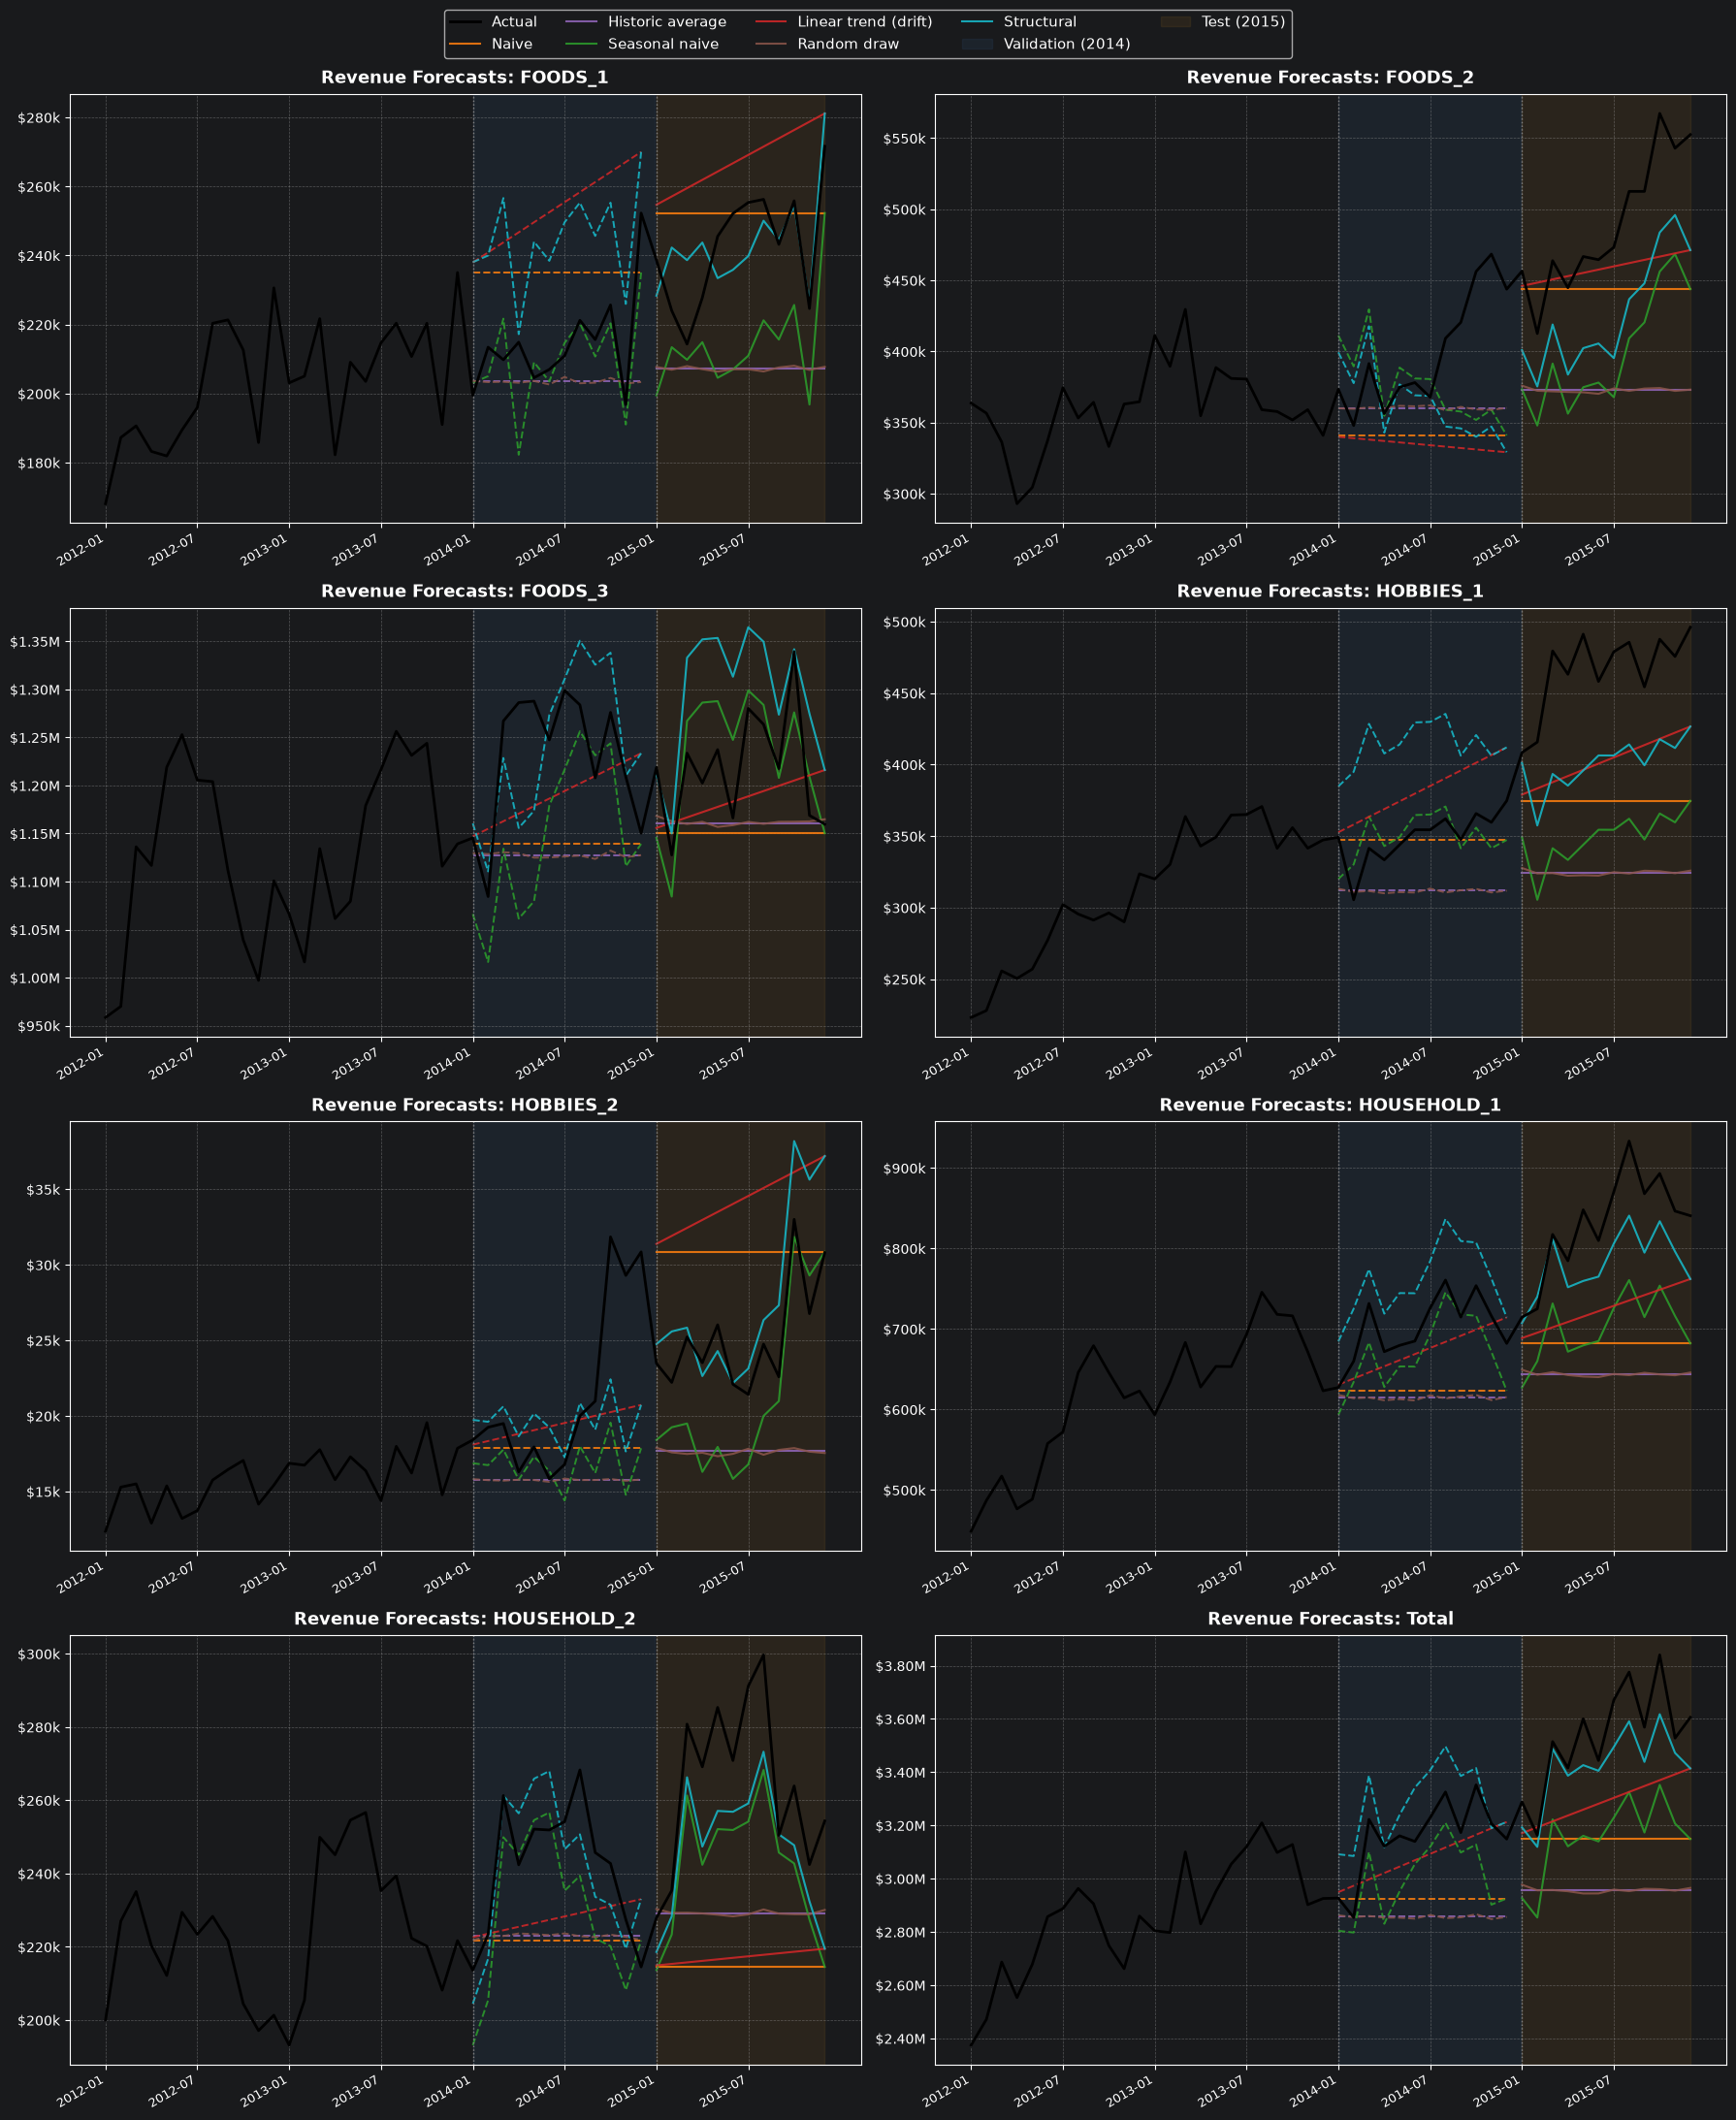

In [8]:
# Color palette for baseline models
palette = {
    "Naive": "#ff7f0e",
    "Historic average": "#9467bd",
    "Seasonal naive": "#2ca02c",
    "Linear trend (drift)": "#d62728",
    "Random draw": "#8c564b",
    "Structural": "#17becf"
}

series_list = [c for c in df_monthly.columns if c != "Total"] + ["Total"]
months = df_monthly.index.tolist()

fig, axes = plt.subplots(4, 2, figsize=(18, 22))
axes = axes.flatten()

for idx, sname in enumerate(series_list):
    ax = axes[idx]
    y_full = df_monthly[sname].values
    
    # Actual series
    ax.plot(range(48), y_full, color="black", linewidth=2.0, label="Actual" if idx == 0 else "", zorder=5)
    
    # 1. Validation Forecasts (2014, months 24:36)
    y_tr_val = y_full[:24]
    for mname, mfn in baseline_models.items():
        y_fc_val = mfn(y_tr_val, h=12)
        ax.plot(range(24, 36), y_fc_val, color=palette[mname], linestyle="--", linewidth=1.4, alpha=0.85)
        
    # 2. Test Forecasts (2015, months 36:48)
    y_tr_test = y_full[:36]
    for mname, mfn in baseline_models.items():
        y_fc_test = mfn(y_tr_test, h=12)
        ax.plot(range(36, 48), y_fc_test, color=palette[mname], linestyle="-", linewidth=1.5, alpha=0.85,
                label=mname if idx == 0 else "")
        
    # Background shading and markers
    ax.axvspan(24, 35.9, color="#4a90e2", alpha=0.08, label="Validation (2014)" if idx == 0 else "")
    ax.axvspan(36, 47, color="#f5a623", alpha=0.08, label="Test (2015)" if idx == 0 else "")
    ax.axvline(24, color="gray", linestyle=":", linewidth=1.0)
    ax.axvline(36, color="gray", linestyle=":", linewidth=1.0)
    
    ax.set_title(f"Revenue Forecasts: {sname}", fontsize=13, fontweight="bold", pad=8)
    ax.set_xticks(range(0, 48, 6))
    ax.set_xticklabels([months[i] for i in range(0, 48, 6)], rotation=30, ha="right", fontsize=9)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, p: f"${v*1e-3:,.0f}k" if v < 1e6 else f"${v*1e-6:,.2f}M"))
    ax.grid(True, linestyle="--", alpha=0.4)

# Create a clean unified legend
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.995), ncol=5, fontsize=11, frameon=True)

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()


## Step 5 - Assessment

Based on the error metrics tables and visual analysis across the validation (2014) and test (2015) horizons, we address the key questions:

### 1. Is there a best baseline?
**No single baseline is universally superior in every scenario**, but **Structural (Seasonal Naive + Drift)** is by far the strongest model overall when seasonal patterns and continuous growth co-occur.
- On the aggregate **Total revenue** series:
  - In the **Validation window (2014)**, **Linear Trend** achieved the lowest wMAPE ($3.43\%$) followed by **Structural** ($4.10\%$) and **Seasonal Naive** ($5.12\%$).
  - In the **Test window (2015)**, **Structural** is the unambiguous winner on Total revenue: **wMAPE of $3.23\%$**, **RMSE of \$134,238**, and **MASE of 0.53** (compared to $7.00\%$ for Linear Trend and $10.74\%$ for Seasonal Naive).
- For series dominated by seasonality with slower growth (e.g., `FOODS_3`), pure **Seasonal Naive** is best ($3.61\%$ wMAPE on test).
- For series with steep trend expansion (e.g., `FOODS_2` and `HOBBIES_1`), **Linear Trend** or **Structural** perform best.
- **Naive**, **Historic Average**, and **Random Draw** consistently perform the worst across all departments because they cannot accommodate seasonality or trend simultaneously.

---

### 2. Is one baseline consistently better across all seven departments?
**No.** The underlying dynamics differ fundamentally across departments:
- **`FOODS_3`** (the single largest department, generating over \$14M/year): Sales growth plateaued around 2013–2014. Because there was no strong multi-year drift, pure **Seasonal Naive** performed best (wMAPE $3.61\%$), whereas drift-adjusted models over-forecasted.
- **`FOODS_2` & `HOBBIES_1`:** Both experienced rapid upward growth from 2012 to 2015. Here, **Linear Trend** performed best (wMAPE $7.73\%$ and $13.59\%$, respectively), while Seasonal Naive lagged behind because it under-forecasted the expanding trend.
- **`HOUSEHOLD_1`, `HOUSEHOLD_2`, & `FOODS_1`:** Displayed both marked summer/spring seasonality and sustained growth. For these three, **Structural** clearly dominated on Test (wMAPEs of $6.15\%$, $6.77\%$, and $4.54\%$).
Hence, no single baseline is universally optimal across all departments.

---

### 3. Does the picture change between validation and test?
**Yes, significantly:**
1. **Changing trend velocity:** Between 2012 and 2013 (the validation training window), the stores experienced initial expansion, giving higher drift rates that slightly moderated in 2014. By 2015 (test window), categories like `FOODS_3` flattened out while `FOODS_2` and `HOBBIES_1` surged.
2. **Model rank shifts:**
   - In `FOODS_2`, the transition between 2013 and 2014 was relatively flat, leading `Random Draw / Historic Average` to rank best on Validation ($10.34\%$ wMAPE). In the 2015 test window, strong growth resumed, causing Historic Average error to skyrocket to $23.71\%$ while `Linear Trend` became best ($7.73\%$).
   - In `HOBBIES_1`, simple `Naive` was best in validation ($3.68\%$ wMAPE) due to year-end alignment, but in the 2015 test window Naive degraded to $19.62\%$ and `Linear Trend` was best ($13.59\%$).
   - In `FOODS_1`, `Seasonal Naive` was best in 2014 ($3.98\%$ wMAPE), but `Structural` took the lead in 2015 ($4.54\%$ wMAPE).

---

### 4. Department-Level Model Selection & Aggregated 2015 Forecast Deviation
We evaluate the aggregated full-year 2015 forecast using two well-defined rules:

- **Rule A (Validation-Selected Rule — Best Practice):**  
  To avoid data leakage, we select for each department the baseline with the **lowest wMAPE on the 2014 Validation window**, then apply those selected models to the 2015 Test window and aggregate their forecasts across all seven departments.
- **Rule B (Ex-Post Test Oracle):**  
  Select the best baseline directly on the 2015 Test window for each department.

#### Ways to Report the Full-Year Deviation:
There are two primary ways to report the annual forecast deviation:
1. **Net Annual Dollar Deviation & Percentage Error:**  
   $$\text{Net Deviation} = \sum_{d=1}^7 \sum_{h=1}^{12} \hat{y}_{d,h} - \sum_{d=1}^7 \sum_{h=1}^{12} y_{d,h}, \quad \% \text{ Deviation} = \frac{\text{Net Deviation}}{\text{Actual Total}} \times 100\%$$
   *Justification:* From an executive budgeting and corporate finance perspective, this measures the bottom-line annual fiscal discrepancy, allowing intra-year monthly timing differences to offset.
2. **Monthly Aggregated wMAPE / Absolute Deviation:**  
   $$\text{wMAPE}_{\text{agg}} = \frac{\sum_{h=1}^{12} |\sum_{d=1}^7 \hat{y}_{d,h} - \sum_{d=1}^7 y_{d,h}|}{\sum_{h=1}^{12} \sum_{d=1}^7 y_{d,h}} \times 100\%$$
   *Justification:* From a supply-chain and warehouse operations perspective, positive errors in high-demand months do not forgive inventory shortages in low-demand months. Monthly wMAPE accurately reflects monthly planning errors.


In [9]:
depts = [c for c in df_monthly.columns if c != "Total"]

# Actual 2015 values
y_actual_2015_depts = {d: df_monthly[d].loc["2015-01":"2015-12"].values for d in depts}
actual_2015_total_monthly = df_monthly["Total"].loc["2015-01":"2015-12"].values
actual_2015_annual = float(np.sum(actual_2015_total_monthly))

# --- Rule A: Selected on Validation 2014 (Minimizing Validation wMAPE) ---
rule_a_picks = {}
for d in depts:
    best_m = val_tables[list(baseline_models.keys())[0]].index
    best_model = min(baseline_models.keys(), key=lambda m: val_tables[m].loc[d, "wMAPE (%)"])
    rule_a_picks[d] = best_model

fc_2015_rule_a = {}
for d in depts:
    y_tr = df_monthly[d].loc["2012-01":"2014-12"].values
    fc_2015_rule_a[d] = baseline_models[rule_a_picks[d]](y_tr, h=12)

agg_fc_2015_rule_a = np.sum(list(fc_2015_rule_a.values()), axis=0)
annual_fc_rule_a = float(np.sum(agg_fc_2015_rule_a))
net_diff_rule_a = annual_fc_rule_a - actual_2015_annual
pct_diff_rule_a = (net_diff_rule_a / actual_2015_annual) * 100.0
monthly_wmape_rule_a = (np.sum(np.abs(actual_2015_total_monthly - agg_fc_2015_rule_a)) / actual_2015_annual) * 100.0

# --- Rule B: Ex-post best on Test 2015 ---
rule_b_picks = {}
for d in depts:
    best_model = min(baseline_models.keys(), key=lambda m: test_tables[m].loc[d, "wMAPE (%)"])
    rule_b_picks[d] = best_model

fc_2015_rule_b = {}
for d in depts:
    y_tr = df_monthly[d].loc["2012-01":"2014-12"].values
    fc_2015_rule_b[d] = baseline_models[rule_b_picks[d]](y_tr, h=12)

agg_fc_2015_rule_b = np.sum(list(fc_2015_rule_b.values()), axis=0)
annual_fc_rule_b = float(np.sum(agg_fc_2015_rule_b))
net_diff_rule_b = annual_fc_rule_b - actual_2015_annual
pct_diff_rule_b = (net_diff_rule_b / actual_2015_annual) * 100.0
monthly_wmape_rule_b = (np.sum(np.abs(actual_2015_total_monthly - agg_fc_2015_rule_b)) / actual_2015_annual) * 100.0

# Display Selection Tables
picks_df = pd.DataFrame({
    "Rule A Pick (Val wMAPE)": [f"{rule_a_picks[d]} ({val_tables[rule_a_picks[d]].loc[d, 'wMAPE (%)']:.2f}%)" for d in depts],
    "Rule B Pick (Test wMAPE)": [f"{rule_b_picks[d]} ({test_tables[rule_b_picks[d]].loc[d, 'wMAPE (%)']:.2f}%)" for d in depts],
}, index=depts)

print("=== BEST BASELINE PER DEPARTMENT ===")
display(picks_df)

# Aggregation Comparison Table
results_summary = pd.DataFrame([
    {
        "Selection Strategy": "Rule A: Validation-Selected (Best Practice)",
        "Actual 2015 Revenue": f"${actual_2015_annual:,.2f}",
        "Aggregated Forecast": f"${annual_fc_rule_a:,.2f}",
        "Net Dollar Error": f"${net_diff_rule_a:,.2f}",
        "Annual Relative Deviation (%)": f"{pct_diff_rule_a:+.2f}%",
        "Monthly Aggregated wMAPE (%)": f"{monthly_wmape_rule_a:.2f}%",
    },
    {
        "Selection Strategy": "Rule B: Ex-Post Test Oracle (Theoretical Upper Bound)",
        "Actual 2015 Revenue": f"${actual_2015_annual:,.2f}",
        "Aggregated Forecast": f"${annual_fc_rule_b:,.2f}",
        "Net Dollar Error": f"${net_diff_rule_b:,.2f}",
        "Annual Relative Deviation (%)": f"{pct_diff_rule_b:+.2f}%",
        "Monthly Aggregated wMAPE (%)": f"{monthly_wmape_rule_b:.2f}%",
    }
]).set_index("Selection Strategy")

print("\n=== AGGREGATED 2015 FULL-YEAR FORECAST DEVIATIONS ===")
display(results_summary)


=== BEST BASELINE PER DEPARTMENT ===


,Rule A Pick (Val wMAPE),Rule B Pick (Test wMAPE)
FOODS_1,Seasonal naive (3.98%),Structural (4.54%)
FOODS_2,Random draw (10.34%),Linear trend (drift) (7.73%)
FOODS_3,Structural (4.70%),Seasonal naive (3.61%)
HOBBIES_1,Naive (3.68%),Linear trend (drift) (13.59%)
HOBBIES_2,Linear trend (drift) (17.00%),Structural (12.06%)
HOUSEHOLD_1,Seasonal naive (4.78%),Structural (6.15%)
HOUSEHOLD_2,Structural (4.65%),Structural (6.77%)



=== AGGREGATED 2015 FULL-YEAR FORECAST DEVIATIONS ===


,Actual 2015 Revenue,Aggregated Forecast,Net Dollar Error,Annual Relative Deviation (%),Monthly Aggregated wMAPE (%)
Selection Strategy,,,,,
Rule A: Validation-Selected (Best Practice),"$42,416,456.61","$38,854,479.11","$-3,561,977.50",-8.40%,8.40%
Rule B: Ex-Post Test Oracle (Theoretical Upper Bound),"$42,416,456.61","$40,662,521.29","$-1,753,935.32",-4.14%,4.14%
